# Signal search (JPM, h=10, N=55)

Exploration after the paper run: can the state-conditioned net beat a uniform forecast at h=10 by tuning
the soft-label width, the training budget, the number of features (top-k by mutual information), and how
stable is it over seeds?

All splits, feature scaling and state bins here are fit on the h=10 train window. The "best" numbers at
the end pick the lowest test NLL across settings, so they are optimistic.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "markov").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from torch.utils.data import DataLoader

from markov.data import load_jpm, splits_by_horizon, standardize, return_states, forward_labels
from markov.models import make_model
from markov.train import loaders, dataset, fit
from markov.metrics import evaluate, baselines
from markov.plots import save

H, N, K = 10, 55, 30
ALPHAS = [1e-6, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 5.0, 10.0]
TAUS = [10, 50, 100, 200, 500, 1000]
OUT_S = ROOT / "results/single_asset/signal_search"
OUT_O = ROOT / "results/single_asset/optimal_setup"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
prices, F, cols = load_jpm()
sp = splits_by_horizon(len(prices) - 1, [H])
F = standardize(F, sp[H]["idx_train"])
X, n_x, _ = return_states(prices, 55, len(sp[H]["idx_train"]))
c = forward_labels(prices, sp, [N])[(H, N)]
n = c["N_actual"]
mi = mutual_info_classif(F[c["idx_train"]], c["y_all"][c["idx_train"]], random_state=0, n_neighbors=5)
ranking = np.argsort(mi)[::-1]
assert (ranking[:K] == np.load(OUT_O / "selected_feature_indices.npy")).all()
print(f"top {K} features:", [cols[i] for i in ranking[:K]])


def tag(s):
    return f"{s:.4f}".replace(".", "p")


def run(Fk, path, sigma, seed=0, **kw):
    # train (or load) one state-conditioned net and return train / val / test NLL
    tr, va, te = loaders(Fk, X, c["y_all"], c)
    torch.manual_seed(seed)
    np.random.seed(seed)
    model, _ = fit(make_model("state_cond", Fk.shape[1], n_x, n), path, tr, va, n, sigma, DEVICE, **kw)
    tr_eval = DataLoader(dataset(Fk, X, c["y_all"], c["idx_train"]), batch_size=512)
    out = {s: -evaluate(model, l, n, DEVICE)["mean_ll"] for s, l in [("train_nll", tr_eval), ("val_nll", va), ("test_nll", te)]}
    return {**out, "gen_gap": out["test_nll"] - out["train_nll"]}

top 30 features: ['Total net revenue', 'Principal transactions', 'Goodwill, MSRs and other intangible assets', 'Return on Avg Tangible Equity', 'Operating Income', 'Trading liabilities.y', 'Avg Securities/Earning Assets', 'Avg Loans/Deposits', 'Loans/Deposits (%)', 'Trading assets included assets pledged', 'Total Assets', 'Total Deposits', 'Provision for credit losses.y', 'Net Int. Inc. after Loan Loss Provision', 'Compensation expense', "Total Shareholders' Equity", 'Accounts payable and other liabilities.x', 'Accrued interest and accounts receivable.y', 'PPNR/Avg Assets', 'Other', 'Trading liabilities.x', 'Accumulated other comprehensive income / loss', 'EPS (recurring)', 'Marketing', 'Loan Loss Provision', 'Total noninterest expense', 'Tangible Assets', 'Proceeds from paydowns and maturities', 'Income tax expense / benefit', 'Net decrease / increase in cash and due from banks']


In [3]:
bl = baselines(c, X, n_x, ALPHAS, TAUS)
base = pd.DataFrame([{"baseline": "uniform", "test_nll": np.log(n)}] +
                    [{"baseline": k, "test_nll": -bl[k]["test_ll"]} for k in ["marginal", "additive", "backoff"]])
base.to_csv(OUT_S / "baseline_check.csv", index=False)
print(base.round(4).to_string(index=False))

baseline  test_nll
 uniform    4.0073
marginal    4.0073
additive    4.0076
 backoff    4.0073


## Soft-label width (sigma 0 means 1e-9, a one-hot target in float32)

In [4]:
rows = []
for s in [0.0, 0.1, 0.25, 0.5, 1.0]:
    r = run(F[:, ranking[:K]], OUT_S / f"cache/sigswp_sa{tag(s)}_h{H}_N{N}_nf{K}.pt", s or 1e-9)
    rows.append({"sigma_anchor": s, "sigma_train": s or 1e-9, **r})
sig = pd.DataFrame(rows)
sig.to_csv(OUT_S / "sigma_sweep.csv", index=False)
best = sig.loc[sig.val_nll.idxmin(), "sigma_anchor"]
print(sig.round(4).to_string(index=False), f"\nbest sigma on val: {best}")

 sigma_anchor  sigma_train  train_nll  val_nll  test_nll  gen_gap
         0.00         0.00     4.0052   4.0142    4.0091   0.0039
         0.10         0.10     4.0052   4.0142    4.0091   0.0039
         0.25         0.25     4.0052   4.0142    4.0091   0.0039
         0.50         0.50     4.0037   4.0140    4.0084   0.0046
         1.00         1.00     3.8835   3.9942    4.0060   0.1225 
best sigma on val: 1.0


## Training budget and feature count at the best sigma

In [5]:
rows = []
for label, epochs, patience in [("A_orig", 100, 10), ("B_ext", 200, 25)]:
    r = run(F[:, ranking[:K]], OUT_S / f"cache/budget_{label}_sa{tag(best)}_h{H}_N{N}_nf{K}.pt", best,
            max_epochs=epochs, patience=patience)
    rows.append({"budget": label, "max_epochs": epochs, "patience": patience, "sigma_anchor": best, **{k: r[k] for k in ["train_nll", "val_nll", "test_nll"]}})
budget = pd.DataFrame(rows)
budget.to_csv(OUT_S / "training_budget.csv", index=False)

rows = []
for k in [30, 50, 194]:
    idx = ranking[:k] if k < 194 else np.arange(194)
    rows.append({"n_features": k, "sigma_anchor": best, **run(F[:, idx], OUT_S / f"cache/featswp_nf{k}_sa{tag(best)}_h{H}_N{N}.pt", best)})
feat = pd.DataFrame(rows)
feat.to_csv(OUT_S / "feature_sweep.csv", index=False)
print(budget.round(4).to_string(index=False), "\n")
print(feat.round(4).to_string(index=False))

budget  max_epochs  patience  sigma_anchor  train_nll  val_nll  test_nll
A_orig         100        10           1.0     3.8835   3.9942     4.006
 B_ext         200        25           1.0     3.8835   3.9942     4.006 

 n_features  sigma_anchor  train_nll  val_nll  test_nll  gen_gap
         30           1.0     3.8835   3.9942    4.0060   0.1225
         50           1.0     3.8889   3.9896    4.0523   0.1634
        194           1.0     3.9297   3.9979    4.0078   0.0781


In [6]:
best_nll = min(sig.test_nll.min(), budget.test_nll.min(), feat.test_nll.min())
summary = pd.DataFrame({"metric": ["uniform_nll", "marginal_nll", "additive_nll", "best_neural_nll_on_test", "delta_vs_uniform"],
                        "value": [np.log(n), -bl["marginal"]["test_ll"], -bl["additive"]["test_ll"], best_nll, np.log(n) - best_nll]})
summary.to_csv(OUT_S / "final_summary.csv", index=False)
print(summary.round(4).to_string(index=False))

                 metric  value
            uniform_nll 4.0073
           marginal_nll 4.0073
           additive_nll 4.0076
best_neural_nll_on_test 4.0060
       delta_vs_uniform 0.0013


## Seed stability with the top 30 features (seeds 0 to 4) and a feature-count ablation

 seed  train_nll  val_nll  test_nll
    0     3.8835   3.9942    4.0060
    1     3.9042   3.9763    4.0296
    2     4.0081   4.0066    4.0074
    3     3.9133   3.9899    4.0223
    4     4.0085   4.0116    4.0108 
mean test NLL 4.0152 (std 0.0103), uniform 4.0073


 n_features  train_nll  val_nll  test_nll  gen_gap
         15     3.8650   3.9697    4.1030   0.2380
         30     3.8835   3.9942    4.0060   0.1225
         50     3.8889   3.9896    4.0523   0.1634
        194     3.9289   3.9952    4.0050   0.0761


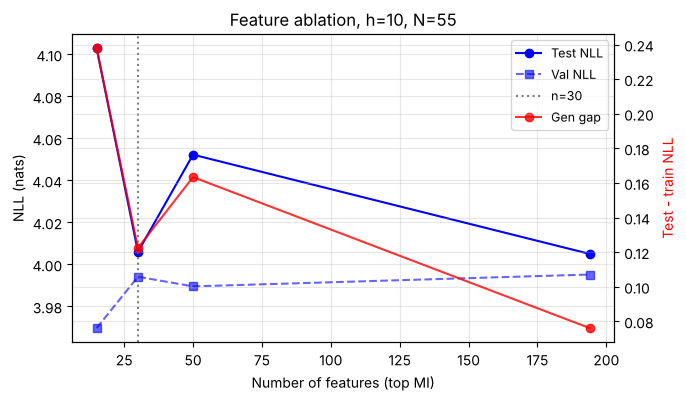

In [7]:
rows = [{"seed": s, **run(F[:, ranking[:K]], OUT_O / f"cache/seed{s}_h{H}_N{N}_nfeat{K}.pt", c["sigma"], seed=s)} for s in range(5)]
seeds = pd.DataFrame(rows).drop(columns="gen_gap")
seeds.to_csv(OUT_O / "seed_stability.csv", index=False)
print(seeds.round(4).to_string(index=False), f"\nmean test NLL {seeds.test_nll.mean():.4f} (std {seeds.test_nll.std():.4f}), uniform {np.log(n):.4f}")

rows = [{"n_features": k, **run(F[:, ranking[:k]], OUT_O / f"cache/fabl_n{k}_h{H}_N{N}_seed0.pt", c["sigma"])} for k in [15, 30, 50, 194]]
fa = pd.DataFrame(rows)
fa.to_csv(OUT_O / "feature_ablation_h10.csv", index=False)
print(fa.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(fa.n_features, fa.test_nll, "o-b", label="Test NLL")
ax.plot(fa.n_features, fa.val_nll, "s--b", alpha=0.6, label="Val NLL")
ax.axvline(K, color="gray", ls=":", label=f"n={K}")
ax2 = ax.twinx()
ax2.plot(fa.n_features, fa.gen_gap, "o-r", alpha=0.8, label="Gen gap")
ax.set(xlabel="Number of features (top MI)", ylabel="NLL (nats)", title=f"Feature ablation, h={H}, N={N}")
ax2.set_ylabel("Test - train NLL", color="r")
ax.legend(ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0],
          ax.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1], fontsize=9)
save(fig, OUT_O / f"figures/feature_ablation_h{H}_N{N}")
plt.show()

pd.DataFrame({"metric": ["mean_test_nll", "std_test_nll", "uniform_nll", "marginal_nll", "additive_nll", "backoff_nll", "information_gain"],
              "value": [seeds.test_nll.mean(), seeds.test_nll.std(), np.log(n), -bl["marginal"]["test_ll"], -bl["additive"]["test_ll"],
                        -bl["backoff"]["test_ll"], np.log(n) - seeds.test_nll.mean()]}).to_csv(OUT_O / "final_summary.csv", index=False)